# RAUSNet: synovitis classification on joint ultrasound with CNNs

**Final project, AI for Biomedical Engineers: Intelligent Medical Image Classification.**

This notebook reproduces the methodology of the technical report, step by step:

| Project section | Cells |
|---|---|
| 2.A Data preprocessing | scale normalization, resizing, data cleaning and data augmentation |
| 2.B Model description | pre-trained EfficientNet-B0 (transfer learning) with two heads |
| 2.C Training and testing | split, hyperparameters, accuracy, sensitivity, specificity and confusion matrix |
| 3. Deployment and testing with new images | model files and inference on images the model never saw |

**Task.** Grade synovitis in the MCP2, MCP3 and wrist joints on the EULAR-OMERACT scale (0 to 3), separately
for grey scale (GS) and Power Doppler (PD). The combined grade is computed with the official rule: 0 if GS = 0;
otherwise, the larger of GS and PD.

> Research use only. The images are synthetic and the model is not clinically validated.

**How to run it.** Locally, from the repository root with the `.venv` environment. On Google Colab, the first
cell clones the repository and installs the dependencies. If the images are missing, it generates them (the
generator is deterministic, so exactly the same images are produced).

In [1]:
# Setup: works locally (repository checkout) and on Google Colab.
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not Path("/content/rausnet").exists():
        !git clone -q --depth 1 -b PIA_devl https://github.com/JB-GB/AI_for_Biomedical_Engineers.git /content/rausnet
    %cd /content/rausnet
    %pip install -q -e . onnxruntime scikit-learn

# Repository root = folder that holds pyproject.toml
REPO = Path.cwd()
while not (REPO / "pyproject.toml").exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO / "src"))
os.chdir(REPO)

# Where the images live (outside the repository; no patient data is ever committed)
DATA_DIR = Path(os.environ.get("RAUSNET_DATA_DIR", "/content/data" if IN_COLAB else "J:/rausnet_data"))
MODEL_DIR = REPO / "release" / "workspace" / "models" / "v0005"      # deployed model version
MANIFEST = REPO / "release" / "workspace" / "data" / "datasets" / "v0005" / "manifest.csv"
FIG_DIR = REPO / "docs" / "paper" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
print("repository:", REPO)
print("data:", DATA_DIR)
print("model:", MODEL_DIR)

repository: J:\JB-GB\AI_for_Biomedical_Engineers
data: J:\rausnet_data
model: J:\JB-GB\AI_for_Biomedical_Engineers\release\workspace\models\v0005


In [2]:
import json
import warnings
from collections import Counter

warnings.filterwarnings("ignore", message="IProgress not found")

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

from rausnet.data.manifest import read_manifest
from rausnet.data.split import split_records
from rausnet.data.synthetic import generate_dataset
from rausnet.grading import combined_score
from rausnet.metrics import quadratic_weighted_kappa, bootstrap_ci
from rausnet.serve.inference import Predictor, preprocess

GRADE_NAMES = ["0 normal", "1 mild", "2 moderate", "3 severe"]
torch.manual_seed(0)
np.random.seed(0)

# Regenerate the deterministic synthetic sets if they are missing (e.g. on a fresh Colab runtime)
spec = json.loads((REPO / "release" / "workspace" / "workspace.json").read_text())
for s in spec["synthetic"]:
    if not (DATA_DIR / s["dir"] / "manifest.csv").exists():
        print("generating", s)
        generate_dataset(DATA_DIR / s["dir"], n_patients=s["patients"], seed=s["seed"], size=s["size"])
print("synthetic sets ready")

synthetic sets ready


## 2.A Data preprocessing

### Dataset
Because there is no public dataset of ultrasound images with synovitis labelled according to EULAR-OMERACT, the
model was developed with a procedural generator of synthetic MCP2-3 and wrist ultrasound images (anatomy,
speckle, acoustic shadow and Doppler signals that follow the scale's coverage definitions). Dataset v0005 has
1 920 GS/PD pairs from 320 synthetic patients.

1920 image pairs from 320 patients
joints: {'MCP2': 640, 'MCP3': 640, 'WRIST': 640}
GS grades: {0: 656, 1: 548, 2: 551, 3: 165}
PD grades: {0: 986, 1: 509, 2: 301, 3: 124}
combined grades: {0: 656, 1: 518, 2: 550, 3: 196}


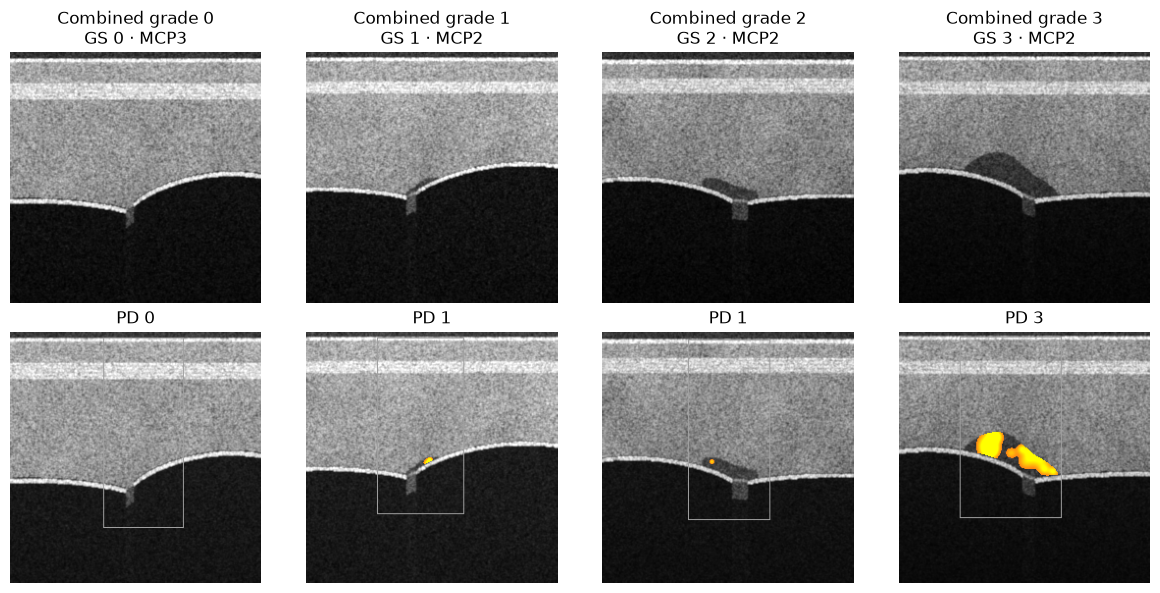

In [3]:
records = read_manifest(MANIFEST)
print(f"{len(records)} image pairs from {len({r.patient_id for r in records})} patients")
print("joints:", dict(Counter(r.joint for r in records)))
print("GS grades:", dict(sorted(Counter(r.gs_grade for r in records).items())))
print("PD grades:", dict(sorted(Counter(r.pd_grade for r in records).items())))
print("combined grades:", dict(sorted(Counter(r.combined_grade for r in records).items())))

# One example per combined grade: GS (anatomy) and PD (blood flow)
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for g in range(4):
    r = next(r for r in records if r.combined_grade == g)
    axes[0, g].imshow(Image.open(DATA_DIR / r.gs_path), cmap="gray")
    axes[0, g].set_title(f"Combined grade {g}\nGS {r.gs_grade} · {r.joint}")
    axes[1, g].imshow(Image.open(DATA_DIR / r.pd_path))
    axes[1, g].set_title(f"PD {r.pd_grade}")
for a in axes.ravel():
    a.axis("off")
plt.tight_layout()
plt.show()

### Scale normalization and resizing
Each pixel (0-255) is divided by 255 to bring it to the [0, 1] range. The GS image gives one channel and the PD
image three colour channels (R, G, B); they are stacked into a **4-channel** tensor, resized to **224 × 224** with
bilinear interpolation (the EfficientNet-B0 input) and finally standardised with mean 0.5 and standard deviation
0.25. The same `preprocess` function is used in training, in the application and in the API, so preprocessing
never differs between stages.

In [4]:
info = json.loads((MODEL_DIR / "model.json").read_text())
spec_in = info["input"]
r = records[0]
raw_gs = np.asarray(Image.open(DATA_DIR / r.gs_path).convert("L"))
raw_pd = np.asarray(Image.open(DATA_DIR / r.pd_path).convert("RGB"))
print("raw GS:", raw_gs.shape, raw_gs.dtype, "range", raw_gs.min(), "-", raw_gs.max())
print("raw PD:", raw_pd.shape, raw_pd.dtype)

scaled = raw_gs.astype(np.float32) / 255.0
print(f"after /255: range {scaled.min():.3f} - {scaled.max():.3f}")

x = preprocess(DATA_DIR / r.gs_path, DATA_DIR / r.pd_path, spec_in["size"], spec_in["mean"], spec_in["std"])
print("network input:", x.shape, x.dtype, f"(mean {spec_in['mean']}, std {spec_in['std']})")
print(f"standardised range: {x.min():.2f} - {x.max():.2f}")

raw GS: (256, 256) uint8 range 7 - 255
raw PD: (256, 256, 3) uint8
after /255: range 0.027 - 1.000
network input: (1, 4, 224, 224) float32 (mean 0.5, std 0.25)
standardised range: -1.89 - 2.00


### Data cleaning
Criteria for discarding an image (the same ones the application applies when it receives new images):

1. The file does not exist or cannot be opened (corrupted image).
2. Format other than PNG, JPG, BMP or TIFF, or a file larger than 20 MB.
3. Shorter side under 64 pixels (low-quality capture).
4. The GS and PD images do not have the same size (they do not correspond to the same view).
5. Grade outside 0-3, duplicated identifier, or PD > 0 without synovium (GS = 0), which the scale does not allow.

For hospital images (stage S3), metadata are also removed and text printed on the image is cropped before it
enters the dataset (`rausnet.data.deid`).

In [5]:
ALLOWED = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
MIN_SIDE, MAX_BYTES = 64, 20 * 1024 * 1024


def check_record(r):
    """Return the reason to discard a record, or None if it is usable."""
    sizes = {}
    for name, rel in (("GS", r.gs_path), ("PD", r.pd_path)):
        p = DATA_DIR / rel
        if not p.exists():
            return f"{name} file missing"
        if p.suffix.lower() not in ALLOWED:
            return f"{name} format {p.suffix}"
        if p.stat().st_size > MAX_BYTES:
            return f"{name} larger than 20 MB"
        try:
            with Image.open(p) as im:
                im.verify()                 # detects truncated / corrupted files
            with Image.open(p) as im:
                sizes[name] = im.size
        except Exception as exc:            # noqa: BLE001 - any decoding error means a corrupt file
            return f"{name} corrupt ({exc.__class__.__name__})"
        if min(sizes[name]) < MIN_SIDE:
            return f"{name} smaller than {MIN_SIDE} px"
    if sizes["GS"] != sizes["PD"]:
        return "GS and PD sizes differ"
    if not (0 <= r.gs_grade <= 3 and 0 <= r.pd_grade <= 3):
        return "grade outside 0-3"
    if r.gs_grade == 0 and r.pd_grade > 0:
        return "PD without synovium"
    return None


seen, discarded = set(), Counter()
clean = []
for r in records:
    reason = "duplicate image_id" if r.image_id in seen else check_record(r)
    seen.add(r.image_id)
    if reason:
        discarded[reason] += 1
    else:
        clean.append(r)
print(f"kept {len(clean)} of {len(records)}; discarded: {dict(discarded) or 'none'}")

kept 1920 of 1920; discarded: none


### Data augmentation
Only during training, and applied equally to the 4 channels: horizontal flip, random crop (85-100 %) rescaled to
224 px, gain change (0.8-1.2) and Gaussian noise with a random level between 0 and 0.03, independent for GS and
PD. The random level is important: with a fixed level the network learned to depend on the noise and failed on
clean images.

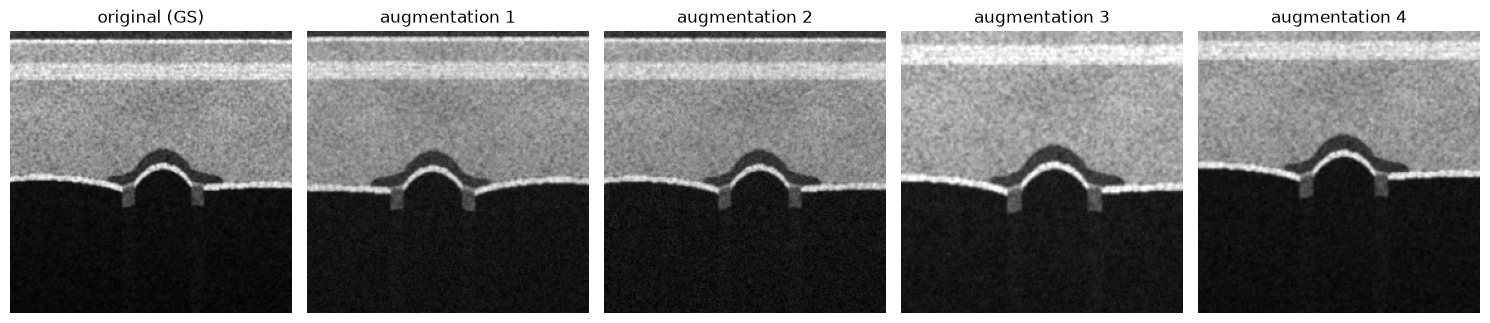

In [6]:
from rausnet.data.dataset import _augment, load_input

x0 = load_input(DATA_DIR / r.gs_path, DATA_DIR / r.pd_path, 224)
fig, axes = plt.subplots(1, 5, figsize=(15, 3.2))
axes[0].imshow(x0[0], cmap="gray")
axes[0].set_title("original (GS)")
for i in range(1, 5):
    axes[i].imshow(_augment(x0.clone())[0], cmap="gray")
    axes[i].set_title(f"augmentation {i}")
for a in axes:
    a.axis("off")
plt.tight_layout()
plt.show()

## 2.B Model description

**Transfer learning with EfficientNet-B0** pre-trained on ImageNet (1.28 million images). The pre-trained weights
already detect edges, textures and shapes, so with few medical images the network only has to adapt those
features to ultrasound. This reduces the data needed, speeds up training and lowers overfitting compared with a
CNN trained from scratch.

We chose EfficientNet-B0 over ResNet50, VGG16 or InceptionV3 because it reaches similar ImageNet accuracy with
far fewer parameters (≈ 4 M vs. 25 M for ResNet50 and 138 M for VGG16), so it runs on a clinic's CPU in about
35 ms per image. In 5-fold cross-validation it tied with ConvNeXt-nano and outperformed ResNet-34 and DeiT-small.

Adaptations:
- The first convolution accepts **4 channels** (GS + PD R, G, B) instead of 3.
- **Two independent heads** (Dropout 0.2 + a 1280-to-4 linear layer): one for GS and one for PD. The combined
  grade is not learned; it is computed with the EULAR-OMERACT rule.

In [7]:
from rausnet.evaluate import load_model

net, cfg = load_model(MODEL_DIR / "model.pt", torch.device("cpu"))
net.eval()
total = sum(p.numel() for p in net.parameters())
heads = sum(p.numel() for p in net.gs_head.parameters()) + sum(p.numel() for p in net.pd_head.parameters())
print(f"backbone: {cfg['model']['backbone']}, input channels: {net.backbone.conv_stem.in_channels}")
print(f"parameters: {total:,} (heads: {heads:,})")
print("GS head:", net.gs_head)
print("PD head:", net.pd_head)

# Feature map sizes through the 7 MBConv stages
with torch.no_grad():
    t = net.backbone.bn1(net.backbone.conv_stem(torch.zeros(1, 4, 224, 224)))
    print(f"stem    -> {tuple(t.shape[1:])}")
    for i, stage in enumerate(net.backbone.blocks, 1):
        t = stage(t)
        print(f"stage {i} -> {tuple(t.shape[1:])}  ({len(stage)} MBConv blocks)")

backbone: efficientnet_b0, input channels: 4
parameters: 4,018,084 (heads: 10,248)
GS head: Sequential(
  (0): Dropout(p=0.2, inplace=False)
  (1): Linear(in_features=1280, out_features=4, bias=True)
)
PD head: Sequential(
  (0): Dropout(p=0.2, inplace=False)
  (1): Linear(in_features=1280, out_features=4, bias=True)
)
stem    -> (32, 112, 112)
stage 1 -> (16, 112, 112)  (1 MBConv blocks)
stage 2 -> (24, 56, 56)  (2 MBConv blocks)
stage 3 -> (40, 28, 28)  (2 MBConv blocks)
stage 4 -> (80, 14, 14)  (3 MBConv blocks)
stage 5 -> (112, 14, 14)  (3 MBConv blocks)
stage 6 -> (192, 7, 7)  (4 MBConv blocks)
stage 7 -> (320, 7, 7)  (1 MBConv blocks)


## 2.C Training and testing

### Dataset splitting
The split is **by patient**: all images of one person fall in the same subset, so the model is not evaluated on
joints of patients it has already seen. We use 70 % training, 15 % validation and 15 % testing. The 85 % of
training + validation corresponds to the 80 % training share in the assignment: the validation set is held out of
it for early stopping and calibration, and the test set stays frozen across model versions. To approach the 20 %
test share, the model is also evaluated on 180 new images (section 3); together, the tests add up to 462 images
(22 %).

In [8]:
splits = split_records(clean, tuple(cfg["data"]["split_ratios"]), cfg["data"]["split_salt"])
n = len(clean)
for name, recs in splits.items():
    print(f"{name:5s}: {len(recs):4d} images ({len(recs) / n:5.1%}), {len({r.patient_id for r in recs})} patients")
overlap = {r.patient_id for r in splits["train"]} & {r.patient_id for r in splits["test"]}
print("patients in both train and test:", len(overlap))

train: 1338 images (69.7%), 223 patients
val  :  300 images (15.6%), 50 patients
test :  282 images (14.7%), 47 patients
patients in both train and test: 0


### Hyperparameters
- **Loss function:** class-weighted multi-class cross-entropy (one per head). It is the 4-class version of
  *binary cross-entropy*; the weights compensate for grade 3 being less frequent.
- **Optimizer:** AdamW (Adam with decoupled weight decay).
- **Epochs:** maximum 30 with early stopping (patience 8) on the validation quadratic weighted kappa.

In [9]:
for k in ("epochs", "batch_size", "lr", "weight_decay", "patience", "class_weighting", "seed"):
    print(f"{k:16s} {cfg['train'][k]}")
card = json.loads((MODEL_DIR / "model_card.json").read_text())
print(f"best epoch: {card['best_epoch']}, trained on: {card['device']}")

epochs           30
batch_size       32
lr               0.0003
weight_decay     0.0001
patience         8
class_weighting  True
seed             42
best epoch: 16, trained on: NVIDIA GeForce RTX 4070 Laptop GPU


**Train again (optional).** Model v0005 is already trained and is the one the application uses. Set
`TRAIN = True` to repeat training with the same configuration (a few minutes with a GPU).

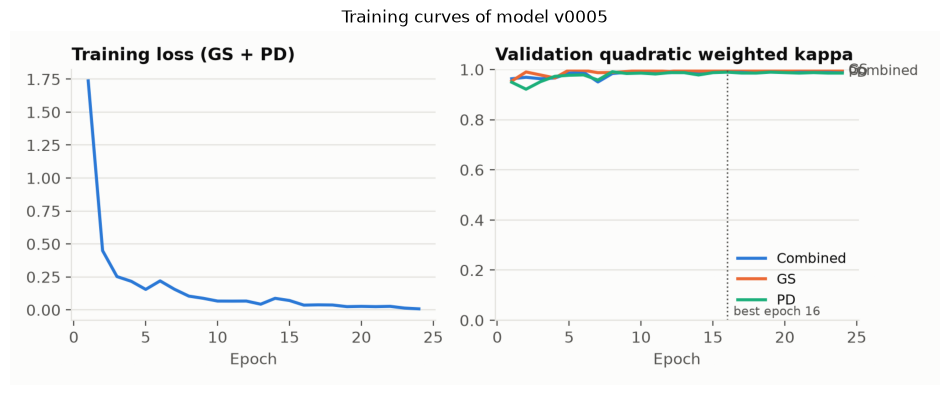

In [10]:
TRAIN = False
if TRAIN:
    import subprocess
    subprocess.run([sys.executable, "-m", "rausnet.train", "--config", "configs/train/baseline.yaml",
                    "--set", f"data.root={DATA_DIR}", f"data.manifest={MANIFEST}"], check=True)
else:
    img = plt.imread(FIG_DIR / "v0005_curves.png")
    plt.figure(figsize=(12, 4.6))
    plt.imshow(img)
    plt.axis("off")
    plt.title("Training curves of model v0005")
    plt.show()

### Performance metrics on the test set
Predictions are made with the exported (ONNX) model, that is, exactly the one the application uses.
- **Accuracy:** proportion of correct predictions.
- **Sensitivity (recall)**, from `sklearn.metrics.classification_report`: of the cases that do have a grade, how
  many the model detects. It is the critical metric for not missing false negatives.
- **Specificity:** of the cases that do not have that grade, how many it correctly rules out. It is obtained from
  the `classification_report` as the *recall* of the negative class (one-vs-rest approach).
- **Confusion matrix.**

In [11]:
predictor = Predictor(MODEL_DIR)


def predict_records(recs, root):
    out = {"gs": [], "pd": [], "comb": [], "conf": [], "y_gs": [], "y_pd": [], "y_comb": [], "groups": []}
    for r in recs:
        res = predictor.predict(root / r.gs_path, root / r.pd_path)
        out["gs"].append(res["gs"]["grade"]); out["pd"].append(res["pd"]["grade"])
        out["comb"].append(res["combined"]["grade"]); out["conf"].append(res["combined"]["confidence"])
        out["y_gs"].append(r.gs_grade); out["y_pd"].append(r.pd_grade); out["y_comb"].append(r.combined_grade)
        out["groups"].append(r.patient_id)
    return {k: np.array(v) for k, v in out.items()}


test = predict_records(splits["test"], DATA_DIR)
print(f"test set: {len(test['comb'])} images, {len(set(test['groups']))} patients")

test set: 282 images, 47 patients


In [12]:
def specificity_table(y_true, y_pred, labels=range(4)):
    """One-vs-rest specificity per class, read from sklearn's classification_report."""
    spec = {}
    for c in labels:
        rep = classification_report(np.array(y_true) == c, np.array(y_pred) == c, output_dict=True, zero_division=0)
        spec[c] = rep["False"]["recall"]       # recall of the negative class = specificity
    return spec


def report(name, y_true, y_pred):
    print(f"=== {name} ===")
    print(classification_report(y_true, y_pred, labels=range(4), target_names=GRADE_NAMES, digits=3, zero_division=0))
    spec = specificity_table(y_true, y_pred)
    print("specificity:", "  ".join(f"{GRADE_NAMES[c]}: {s:.3f}" for c, s in spec.items()))
    print(f"quadratic weighted kappa: {quadratic_weighted_kappa(y_true, y_pred):.3f}\n")


report("Combined grade (EULAR-OMERACT)", test["y_comb"], test["comb"])
report("Grey scale (GS)", test["y_gs"], test["gs"])
report("Power Doppler (PD)", test["y_pd"], test["pd"])

lo, hi = bootstrap_ci(test["y_comb"], test["comb"], test["groups"], n_boot=2000, seed=0)
print(f"combined QWK 95% CI (patient bootstrap): {lo:.3f} - {hi:.3f}")

=== Combined grade (EULAR-OMERACT) ===
              precision    recall  f1-score   support

    0 normal      1.000     1.000     1.000        90
      1 mild      0.989     0.968     0.978        94
  2 moderate      0.957     0.985     0.971        68
    3 severe      1.000     1.000     1.000        30

    accuracy                          0.986       282
   macro avg      0.987     0.988     0.987       282
weighted avg      0.986     0.986     0.986       282

specificity: 0 normal: 1.000  1 mild: 0.995  2 moderate: 0.986  3 severe: 1.000
quadratic weighted kappa: 0.993

=== Grey scale (GS) ===
              precision    recall  f1-score   support

    0 normal      1.000     1.000     1.000        90
      1 mild      1.000     1.000     1.000        99
  2 moderate      1.000     1.000     1.000        67
    3 severe      1.000     1.000     1.000        26

    accuracy                          1.000       282
   macro avg      1.000     1.000     1.000       282
weighted 

**Binary screening.** For the practical clinical decision (refer to the rheumatologist?), grades are grouped into
mild or absent synovitis (0-1) vs. moderate or severe (2-3), and sensitivity and specificity are computed.

In [13]:
def binary_screening(y_true, y_pred, name):
    yt, yp = (np.array(y_true) >= 2).astype(int), (np.array(y_pred) >= 2).astype(int)
    rep = classification_report(yt, yp, target_names=["0-1 mild/absent", "2-3 moderate/severe"],
                                output_dict=True, zero_division=0)
    print(f"{name}: accuracy {rep['accuracy']:.3f} | sensitivity {rep['2-3 moderate/severe']['recall']:.3f} "
          f"| specificity {rep['0-1 mild/absent']['recall']:.3f} | n = {len(yt)}")
    return rep


bin_test = binary_screening(test["y_comb"], test["comb"], "test set")

test set: accuracy 0.986 | sensitivity 0.990 | specificity 0.984 | n = 282


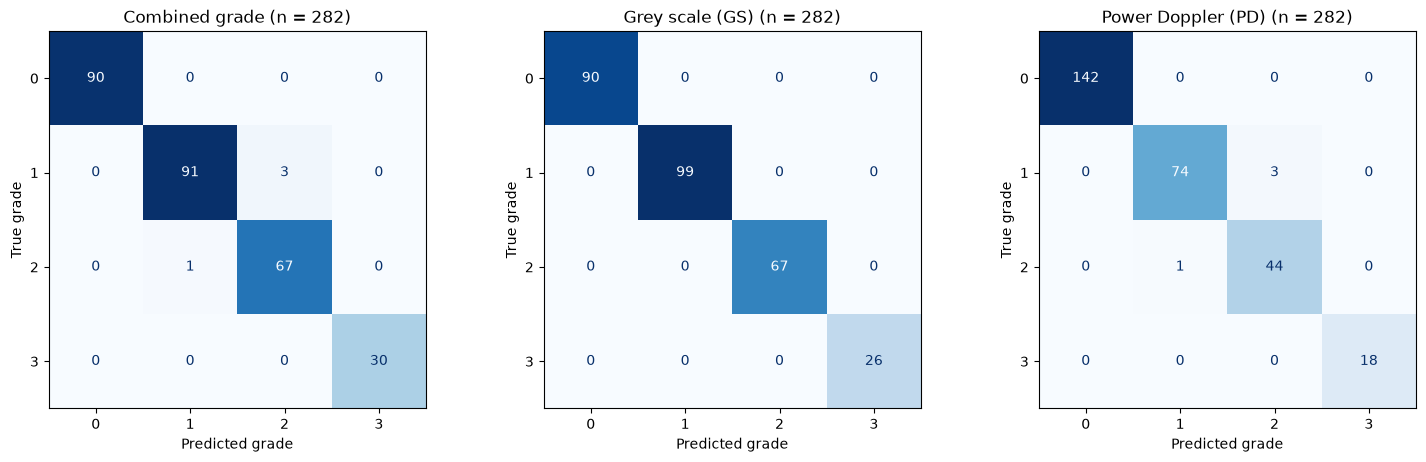

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, (title, yt, yp) in zip(axes, [("Combined grade", test["y_comb"], test["comb"]),
                                     ("Grey scale (GS)", test["y_gs"], test["gs"]),
                                     ("Power Doppler (PD)", test["y_pd"], test["pd"])]):
    ConfusionMatrixDisplay(confusion_matrix(yt, yp, labels=range(4)), display_labels=range(4)).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{title} (n = {len(yt)})")
    ax.set_xlabel("Predicted grade")
    ax.set_ylabel("True grade")
plt.tight_layout()
plt.savefig(FIG_DIR / "nb_confusion_test.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Deployment and testing with new images

### Model saving
The project uses PyTorch, so the equivalent of the Keras `.h5` file is:
- `model.pt`: architecture (configuration) and trained PyTorch weights, for retraining.
- `model.onnx`: model exported to the standard ONNX format, which includes the Grad-CAM maps. The API and the
  desktop application use it with ONNX Runtime, without needing PyTorch.
- `model.json`, `calibration.json` and `model_card.json`: preprocessing, calibration temperature, referral
  threshold and provenance (data, code version, metrics).

In [15]:
for f in sorted(MODEL_DIR.iterdir()):
    print(f"{f.name:18s} {f.stat().st_size / 1e6:7.2f} MB")

# The exported ONNX model gives the same output as the PyTorch weights
import onnxruntime as ort

sess = ort.InferenceSession(str(MODEL_DIR / "model.onnx"), providers=["CPUExecutionProvider"])
with torch.no_grad():
    t_gs, t_pd = net(torch.from_numpy(x))
o_gs, o_pd = sess.run(None, {spec_in["name"]: x})[:2]
print("max |ONNX - PyTorch| logit difference:", float(max(np.abs(o_gs - t_gs.numpy()).max(), np.abs(o_pd - t_pd.numpy()).max())))

calibration.json      0.01 MB
model.json            0.00 MB
model.onnx           16.05 MB
model.pt             16.36 MB
model_card.json       0.00 MB
max |ONNX - PyTorch| logit difference: 7.748603820800781e-06


### Inference with "unseen" images
A new set was generated with another generator seed (42): 180 GS/PD pairs from 30 patients that are not part of
the original dataset (the next cell checks this). From it, 12 example cases are taken, 3 per combined grade. Each
image goes through the **same preprocessing** (resizing to 224 × 224 and normalisation) inside
`Predictor.predict`.

In [16]:
UNSEEN = DATA_DIR / "test_sets" / "synth_seed42"
if not (UNSEEN / "manifest.csv").exists():
    generate_dataset(UNSEEN, n_patients=30, seed=42, size=256)
unseen = read_manifest(UNSEEN / "manifest.csv")
overlap_ids = {r.image_id for r in unseen} & {r.image_id for r in records}
overlap_pat = {r.patient_id for r in unseen} & {r.patient_id for r in records}
print(f"{len(unseen)} unseen pairs, {len({r.patient_id for r in unseen})} patients; "
      f"shared with the training dataset: {len(overlap_ids)} images, {len(overlap_pat)} patients")

# 12 demo cases: 3 per combined grade, from different patients
rng = np.random.default_rng(42)
cases, used = [], set()
for g in range(4):
    pool = [r for r in unseen if r.combined_grade == g and r.patient_id not in used]
    for i in rng.permutation(len(pool))[:3]:
        cases.append(pool[i]); used.add(pool[i].patient_id)
print("demo cases:", len(cases))

180 unseen pairs, 30 patients; shared with the training dataset: 0 images, 0 patients
demo cases: 12


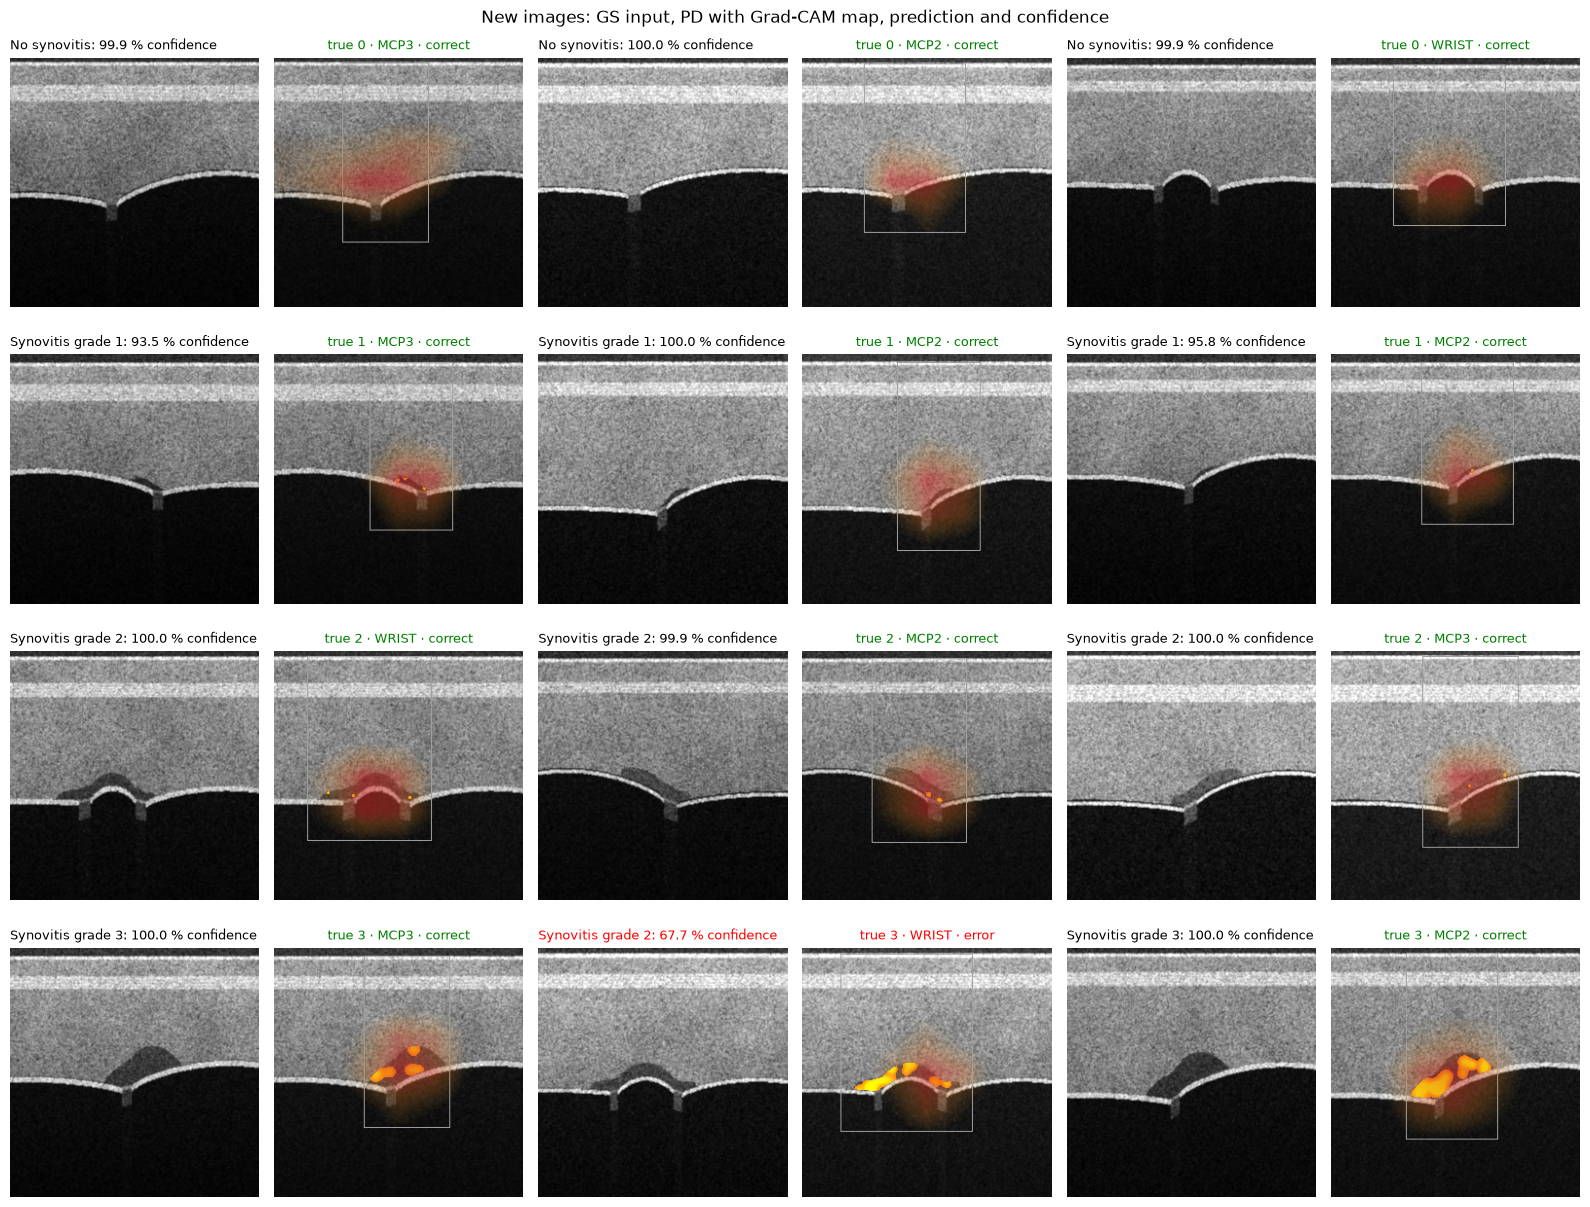

In [17]:
fig, axes = plt.subplots(4, 6, figsize=(16, 12.5))
for k, r in enumerate(cases):
    res = predictor.predict(UNSEEN / r.gs_path, UNSEEN / r.pd_path, explain=True)
    g, conf = res["combined"]["grade"], res["combined"]["confidence"]
    ok = g == r.combined_grade
    ax_gs, ax_pd = axes[k // 3, (k % 3) * 2], axes[k // 3, (k % 3) * 2 + 1]
    ax_gs.imshow(Image.open(UNSEEN / r.gs_path), cmap="gray")
    ax_pd.imshow(res["heatmaps"]["pd"])
    label = "No synovitis" if g == 0 else f"Synovitis grade {g}"
    ax_gs.set_title(f"{label}: {conf * 100:.1f} % confidence", fontsize=9, loc="left",
                    color="black" if ok else "red")
    ax_pd.set_title(f"true {r.combined_grade} · {r.joint} · {'correct' if ok else 'error'}", fontsize=9,
                    color="green" if ok else "red")
    for a in (ax_gs, ax_pd):
        a.axis("off")
plt.suptitle("New images: GS input, PD with Grad-CAM map, prediction and confidence", fontsize=12)
plt.tight_layout()
plt.savefig(FIG_DIR / "nb_unseen_predictions.png", dpi=130, bbox_inches="tight")
plt.show()

### Performance on the 180 new images

=== Combined grade, unseen set ===
              precision    recall  f1-score   support

    0 normal      1.000     1.000     1.000        46
      1 mild      0.986     0.971     0.978        70
  2 moderate      0.947     0.982     0.964        55
    3 severe      1.000     0.889     0.941         9

    accuracy                          0.978       180
   macro avg      0.983     0.961     0.971       180
weighted avg      0.978     0.978     0.978       180

specificity: 0 normal: 1.000  1 mild: 0.991  2 moderate: 0.976  3 severe: 1.000
quadratic weighted kappa: 0.985

combined QWK 95% CI: 0.966 - 0.997
unseen set: accuracy 0.983 | sensitivity 0.984 | specificity 0.983 | n = 180
errors (image, true, predicted): [('SYN042-00001_MCP3_L', 2, 1), ('SYN042-00011_MCP2_R', 1, 2), ('SYN042-00023_WRIST_R', 3, 2), ('SYN042-00027_MCP2_L', 1, 2)]


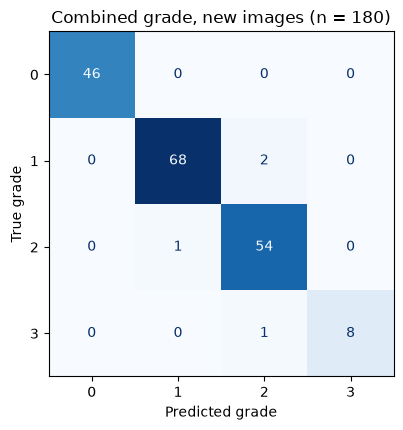

In [18]:
new = predict_records(unseen, UNSEEN)
report("Combined grade, unseen set", new["y_comb"], new["comb"])
lo, hi = bootstrap_ci(new["y_comb"], new["comb"], new["groups"], n_boot=2000, seed=0)
print(f"combined QWK 95% CI: {lo:.3f} - {hi:.3f}")
bin_new = binary_screening(new["y_comb"], new["comb"], "unseen set")
errors = [(r.image_id, r.combined_grade, int(p)) for r, p in zip(unseen, new["comb"]) if r.combined_grade != p]
print("errors (image, true, predicted):", errors)

fig, ax = plt.subplots(figsize=(4.8, 4.4))
ConfusionMatrixDisplay(confusion_matrix(new["y_comb"], new["comb"], labels=range(4)), display_labels=range(4)).plot(
    ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Combined grade, new images (n = {len(new['comb'])})")
ax.set_xlabel("Predicted grade"); ax.set_ylabel("True grade")
plt.tight_layout()
plt.savefig(FIG_DIR / "nb_confusion_unseen.png", dpi=150, bbox_inches="tight")
plt.show()

In [19]:
# Summary table used in the technical report
summary = {}
for name, d, b in (("test", test, bin_test), ("unseen", new, bin_new)):
    rep = classification_report(d["y_comb"], d["comb"], labels=range(4), output_dict=True, zero_division=0)
    summary[name] = {
        "n": int(len(d["comb"])),
        "accuracy": round(rep["accuracy"], 3),
        "qwk": round(quadratic_weighted_kappa(d["y_comb"], d["comb"]), 3),
        "recall": [round(rep[str(c)]["recall"], 3) for c in range(4)],
        "precision": [round(rep[str(c)]["precision"], 3) for c in range(4)],
        "specificity": [round(v, 3) for v in specificity_table(d["y_comb"], d["comb"]).values()],
        "binary_sensitivity": round(b["2-3 moderate/severe"]["recall"], 3),
        "binary_specificity": round(b["0-1 mild/absent"]["recall"], 3),
        "binary_accuracy": round(b["accuracy"], 3),
    }
print(json.dumps(summary, indent=1))
(REPO / "docs" / "paper" / "nb_summary.json").write_text(json.dumps(summary, indent=1))

{
 "test": {
  "n": 282,
  "accuracy": 0.986,
  "qwk": 0.993,
  "recall": [
   1.0,
   0.968,
   0.985,
   1.0
  ],
  "precision": [
   1.0,
   0.989,
   0.957,
   1.0
  ],
  "specificity": [
   1.0,
   0.995,
   0.986,
   1.0
  ],
  "binary_sensitivity": 0.99,
  "binary_specificity": 0.984,
  "binary_accuracy": 0.986
 },
 "unseen": {
  "n": 180,
  "accuracy": 0.978,
  "qwk": 0.985,
  "recall": [
   1.0,
   0.971,
   0.982,
   0.889
  ],
  "precision": [
   1.0,
   0.986,
   0.947,
   1.0
  ],
  "specificity": [
   1.0,
   0.991,
   0.976,
   1.0
  ],
  "binary_sensitivity": 0.984,
  "binary_specificity": 0.983,
  "binary_accuracy": 0.983
 }
}


651

## Conclusion
The model grades synovitis with near-perfect agreement on synthetic data, both on the frozen test set and on new
images, and the application shows the same result with its confidence and heat map. These numbers verify the
complete system; they do **not** measure clinical performance, which requires real anonymised images labelled by
rheumatologists.

**Live demo:** open the RAUSNet application, drag `casoNN_gs.png` and `casoNN_pd.png` from the
`test_sets/synth_seed42_casos` folder (12 pairs from the same new set) and compare with `respuestas.csv`.